# Autonomous Trailer

**Ian Kiprotich - 192026 · Devyan Jethwa - 183428 · Alfred Gitonga - 166342**


## 1. Task
Find the shortest Nairobi-to-Kisumu route after checking road conditions and trailer limits.


## 2. Relevant knowledge
Use our Practical 3 towns and distances. Distances are coursework estimates; closures and vehicle values are test inputs. No live API is used.


In [1]:
import heapq
from copy import deepcopy
from math import isfinite
import pandas as pd
from IPython.display import display, SVG

EDGES = [
    ("Nairobi", "Thika", 45), ("Thika", "Nyeri", 113),
    ("Nairobi", "Naivasha", 90), ("Naivasha", "Nakuru", 70),
    ("Nakuru", "Kericho", 106), ("Kericho", "Kisumu", 85),
    ("Nakuru", "Eldoret", 156), ("Eldoret", "Kisumu", 117)
]
display(pd.DataFrame(EDGES, columns=["From", "To", "Distance (km)"]))


,From,To,Distance (km)
0,Nairobi,Thika,45
1,Thika,Nyeri,113
2,Nairobi,Naivasha,90
3,Naivasha,Nakuru,70
4,Nakuru,Kericho,106
5,Kericho,Kisumu,85
6,Nakuru,Eldoret,156
7,Eldoret,Kisumu,117


## 3. Vocabulary

| Fact | Meaning |
|---|---|
| `(town_a, town_b)` | Directed road |
| `km`, `closed`, `surface` | Distance and condition |
| `height_limit`, `weight_limit` | Maximum height (m) and loaded total weight (tonnes) |
| `blocked`, `excluded`, `caution` | Conclusions from rules |

`None` means a limit is unknown. Each two-way road has two directed entries.


In [2]:
def make_kb():
    roads = {}
    for a, b, km in EDGES:
        for road in [(a, b), (b, a)]:
            roads[road] = {"km": km, "closed": False, "surface": "unknown",
                           "height_limit": None, "weight_limit": None}
    return roads

def add_fact(roads, a, b, fact, value, both=False):
    keys = [(a, b), (b, a)] if both else [(a, b)]
    if any(key not in roads for key in keys):
        raise ValueError("Unknown road")
    if fact not in roads[a, b]:
        raise ValueError("Unknown fact")
    if fact in ["km", "height_limit", "weight_limit"]:
        if value is not None or fact == "km":
            if type(value) not in [int, float] or not isfinite(value) or value <= 0:
                raise ValueError("Distance and limits must be positive numbers")
    elif fact == "closed" and type(value) is not bool:
        raise ValueError("Use True or False for closed")
    elif fact == "surface" and value not in ["dry", "wet", "flooded", "unknown"]:
        raise ValueError("Unknown surface")
    for key in keys:
        roads[key][fact] = value

roads = make_kb()
print(len(roads), "directed roads")


16 directed roads


## 4. General rules
Rules add conclusions until no new facts remain. A blocked road is excluded; unknown limits produce a warning.


In [3]:
# Rule name, condition, conclusion, explanation
rules = [
    ("R1", "closed", "blocked", "Road closed"),
    ("R2", "flooded", "blocked", "Road flooded"),
    ("R3", "too_tall", "blocked", "Trailer exceeds height limit"),
    ("R4", "too_heavy", "blocked", "Vehicle exceeds weight limit"),
    ("R5", "wet", "caution", "Wet road: reassess speed and braking"),
    ("R6", "unknown_limit", "caution", "Verify height and weight limits"),
    ("R7", "unknown_surface", "caution", "Check road surface"),
    ("R8", "blocked", "excluded", "Remove road from route search")
]
display(pd.DataFrame(rules, columns=["Rule", "If", "Then", "Reason"]))

def road_advice(road, truck):
    observations = {
        "closed": road["closed"], "flooded": road["surface"] == "flooded",
        "wet": road["surface"] == "wet", "unknown_surface": road["surface"] == "unknown",
        "unknown_limit": road["height_limit"] is None or road["weight_limit"] is None,
        "too_tall": road["height_limit"] is not None and truck["height_m"] > road["height_limit"],
        "too_heavy": road["weight_limit"] is not None and truck["weight_t"] > road["weight_limit"]
    }
    facts = {name for name, value in observations.items() if value}
    fired, reasons, warnings = set(), [], []
    changed = True
    while changed:
        changed = False
        for name, condition, conclusion, reason in rules:
            if condition in facts and name not in fired:
                fired.add(name)
                reasons.append(name + ": " + reason)
                if conclusion == "caution":
                    warnings.append(reason)
                if conclusion not in facts:
                    facts.add(conclusion)
                    changed = True
    return {"excluded": "excluded" in facts, "reasons": reasons, "warnings": warnings}


,Rule,If,Then,Reason
0,R1,closed,blocked,Road closed
1,R2,flooded,blocked,Road flooded
2,R3,too_tall,blocked,Trailer exceeds height limit
3,R4,too_heavy,blocked,Vehicle exceeds weight limit
4,R5,wet,caution,Wet road: reassess speed and braking
5,R6,unknown_limit,caution,Verify height and weight limits
6,R7,unknown_surface,caution,Check road surface
7,R8,blocked,excluded,Remove road from route search


## 5. Add facts
Test scenario: Nakuru–Kericho is closed in both directions. The Eldoret road is wet, with the example limits below.


In [4]:
add_fact(roads, "Nakuru", "Kericho", "closed", True, both=True)
add_fact(roads, "Nakuru", "Eldoret", "surface", "wet", both=True)
add_fact(roads, "Nakuru", "Eldoret", "height_limit", 4.5, both=True)
add_fact(roads, "Nakuru", "Eldoret", "weight_limit", 35, both=True)
display(pd.DataFrame([{"From": a, "To": b, **facts}
                      for (a, b), facts in roads.items() if a == "Nakuru"]))


,From,To,km,closed,surface,height_limit,weight_limit
0,Nakuru,Naivasha,70,False,unknown,NaN,NaN
1,Nakuru,Kericho,106,True,unknown,NaN,NaN
2,Nakuru,Eldoret,156,False,wet,4.5,35.0


## 6. Delivery inputs
Change the start, destination or truck values here.


In [5]:
start = "Nairobi"
goal = "Kisumu"
truck = {"height_m": 4.2, "weight_t": 28}


## 7. Find a route
Uniform-cost search expands the cheapest frontier entry. The goal is checked when it is popped.


In [6]:
def find_route(roads, start, goal, truck):
    towns = {town for pair in roads for town in pair}
    if start not in towns or goal not in towns:
        raise ValueError("Unknown start or destination")
    for value in [truck["height_m"], truck["weight_t"]]:
        if type(value) not in [int, float] or not isfinite(value) or value <= 0:
            raise ValueError("Truck dimensions must be positive numbers")
    advice = {pair: road_advice(road, truck) for pair, road in roads.items()}
    queue = [(0, start, [start])]
    best, trace = {start: 0}, []
    while queue:
        cost, town, path = heapq.heappop(queue)
        if cost != best[town]:
            continue
        if town != goal:
            for (a, b), road in sorted(roads.items()):
                if a == town and not advice[a, b]["excluded"]:
                    new_cost = cost + road["km"]
                    if new_cost < best.get(b, float("inf")):
                        best[b] = new_cost
                        heapq.heappush(queue, (new_cost, b, path + [b]))
        frontier = [f"{t}: {c}" for c, t, _ in sorted(queue) if c == best[t]]
        trace.append({"Expanded": town, "Cost (km)": cost, "Frontier": ", ".join(frontier)})
        if town == goal:
            warnings = []
            for pair in zip(path, path[1:]):
                warnings.extend(advice[pair]["warnings"])
            return {"path": path, "km": cost, "warnings": sorted(set(warnings)), "trace": trace}
    return {"path": [], "km": None, "warnings": [], "trace": trace}

original = find_route(make_kb(), start, goal, truck)
result = find_route(roads, start, goal, truck)
print("Original graph:", original["km"], "km")
if result["path"]:
    print("Updated route:", " -> ".join(result["path"]))
    print("Distance:", result["km"], "km")
    if result["warnings"]:
        print("Provisional plan:", "; ".join(result["warnings"]))
else:
    print("No route found")
display(pd.DataFrame(result["trace"]))


Original graph: 351 km
Updated route: Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kisumu
Distance: 433 km
Provisional plan: Check road surface; Verify height and weight limits; Wet road: reassess speed and braking


,Expanded,Cost (km),Frontier
0,Nairobi,0,"Thika: 45, Naivasha: 90"
1,Thika,45,"Naivasha: 90, Nyeri: 158"
2,Naivasha,90,"Nyeri: 158, Nakuru: 160"
3,Nyeri,158,Nakuru: 160
4,Nakuru,160,Eldoret: 316
5,Eldoret,316,Kisumu: 433
6,Kisumu,433,


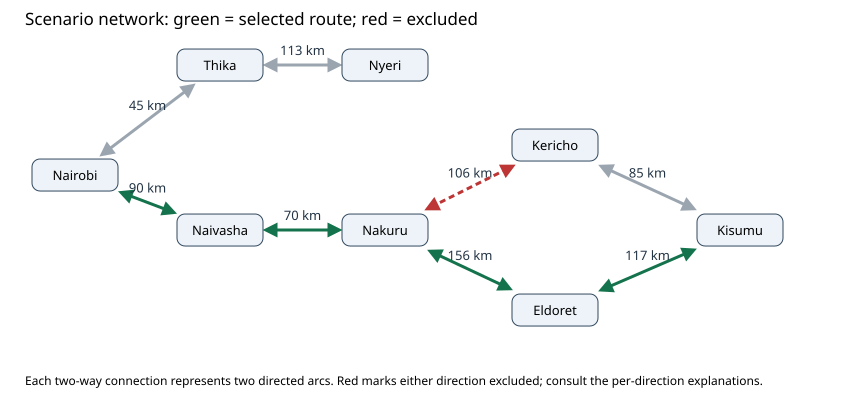

In [7]:
#@title Road network
def draw_network(kb, vehicle, path=()):
    positions = {"Nairobi": (75, 175), "Thika": (220, 65), "Nyeri": (385, 65),
                 "Naivasha": (220, 230), "Nakuru": (385, 230),
                 "Kericho": (555, 145), "Eldoret": (555, 310), "Kisumu": (740, 230)}
    selected = set(zip(path, path[1:]))
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="860" height="410" viewBox="0 0 860 410">',
             '<rect width="860" height="410" fill="white"/>',
             '<defs><marker id="arrow" viewBox="0 0 10 10" refX="5" refY="5" markerWidth="5" markerHeight="5" orient="auto-start-reverse"><path d="M 0 0 L 10 5 L 0 10 z" fill="context-stroke"/></marker></defs>',
             '<text x="25" y="25" font-family="sans-serif" font-size="17">Scenario network: green = selected route; red = excluded</text>']
    for a, b, _ in EDGES:
        x1, y1 = positions[a]; x2, y2 = positions[b]
        dx, dy = x2 - x1, y2 - y1
        inset = min(50 / abs(dx) if dx else float("inf"),
                    23 / abs(dy) if dy else float("inf"))
        blocked = any(road_advice(kb[e], vehicle)["excluded"] for e in [(a, b), (b, a)])
        chosen = (a, b) in selected or (b, a) in selected
        color = "#bd3535" if blocked else "#14734c" if chosen else "#9ba5b0"
        dash = ' stroke-dasharray="6 4"' if blocked else ''
        parts.append(f'<line x1="{x1+dx*inset}" y1="{y1+dy*inset}" x2="{x2-dx*inset}" y2="{y2-dy*inset}" stroke="{color}" stroke-width="3" marker-start="url(#arrow)" marker-end="url(#arrow)"{dash}/>')
        label = f"{kb[a, b]['km']} km"
        parts.append(f'<text x="{(x1+x2)/2}" y="{(y1+y2)/2-10}" text-anchor="middle" font-family="sans-serif" font-size="13" fill="#223344">{label}</text>')
    for name, (x, y) in positions.items():
        parts.append(f'<rect x="{x-43}" y="{y-16}" width="86" height="32" rx="8" fill="#edf3f8" stroke="#31485e"/><text x="{x}" y="{y+5}" text-anchor="middle" font-family="sans-serif" font-size="13">{name}</text>')
    parts.append('<text x="25" y="385" font-family="sans-serif" font-size="12">Each two-way connection represents two directed arcs. Red marks either direction excluded; consult the per-direction explanations.</text></svg>')
    return SVG(''.join(parts))


display(draw_network(roads, truck, result["path"]))


### Search tree from Practical 3
Costs below use the original graph. The closure removes the Kericho branch.


In [8]:
print("""Nairobi (0)
|-- Thika (45) -> Nyeri (158)
`-- Naivasha (90) -> Nakuru (160)
                         |-- Kericho (266) -> Kisumu (351)
                         `-- Eldoret (316) -> Kisumu (433)
""")


Nairobi (0)
|-- Thika (45) -> Nyeri (158)
`-- Naivasha (90) -> Nakuru (160)
                         |-- Kericho (266) -> Kisumu (351)
                         `-- Eldoret (316) -> Kisumu (433)



## 8. Query the knowledge base
Check why a road was excluded. Junction decisions below are simplified simulation rules.


In [9]:
answer = road_advice(roads["Nakuru", "Kericho"], truck)
print("Nakuru -> Kericho")
for reason in answer["reasons"]:
    print(reason)

def junction_action(signal, clear):
    if signal == "red":
        return "Stop"
    if signal == "yellow":
        return "Prepare to stop"
    if signal == "green" and clear is True:
        return "Proceed if other checks pass"
    return "Stop and verify"

print("Green, blocked path:", junction_action("green", False))
print("Green, clear path:", junction_action("green", True))
print("Unknown signal:", junction_action("unknown", True))


Nakuru -> Kericho
R1: Road closed
R6: Verify height and weight limits
R7: Check road surface
R8: Remove road from route search
Green, blocked path: Stop and verify
Green, clear path: Proceed if other checks pass
Unknown signal: Stop and verify


## 9. Test the agent
Check routes, closures, limits and missing observations.


In [10]:
assert original["km"] == 351
assert original["path"] == ["Nairobi", "Naivasha", "Nakuru", "Kericho", "Kisumu"]
assert result["km"] == 433 and "Eldoret" in result["path"]
assert original["warnings"]  # Missing limits must be reported.

test_roads = deepcopy(roads)
add_fact(test_roads, "Nakuru", "Eldoret", "closed", True, both=True)
assert find_route(test_roads, start, goal, truck)["km"] is None
add_fact(test_roads, "Nakuru", "Kericho", "closed", False, both=True)
assert find_route(test_roads, start, goal, truck)["km"] == 351

for fact, value in [("height_limit", 4.0), ("weight_limit", 20), ("surface", "flooded")]:
    test_roads = make_kb()
    add_fact(test_roads, "Nakuru", "Kericho", fact, value)
    assert find_route(test_roads, start, goal, truck)["km"] == 433

test_roads = make_kb()
add_fact(test_roads, "Nakuru", "Kericho", "closed", True)
assert not test_roads["Kericho", "Nakuru"]["closed"]
assert find_route(test_roads, "Kisumu", "Nairobi", truck)["km"] == 351
assert find_route(make_kb(), start, start, truck)["km"] == 0
assert junction_action("red", True) == "Stop"
assert junction_action("green", None) == "Stop and verify"
assert junction_action("green", False) == "Stop and verify"
print("Route, restriction and junction tests passed.")


Route, restriction and junction tests passed.


In [11]:
#@title Extra checks: invalid inputs and shortest paths
def rejects(action):
    try:
        action()
    except ValueError:
        return True
    return False

assert rejects(lambda: find_route(roads, "Atlantis", goal, truck))
assert rejects(lambda: find_route(roads, start, goal, {"height_m": -1, "weight_t": 28}))
assert rejects(lambda: add_fact(test_roads, "Nairobi", "Thika", "km", -1))
assert rejects(lambda: add_fact(test_roads, "Nairobi", "Thika", "closed", "yes"))

def all_paths(roads, start, goal, truck):
    answers = []
    def visit(town, path, cost):
        if town == goal:
            answers.append(cost)
            return
        for (a, b), road in roads.items():
            if a == town and b not in path and not road_advice(road, truck)["excluded"]:
                visit(b, path + [b], cost + road["km"])
    visit(start, [start], 0)
    return answers

comparisons = 0
for scenario in [make_kb(), roads, test_roads]:
    towns = sorted({town for pair in scenario for town in pair})
    for a in towns:
        for b in towns:
            costs = all_paths(scenario, a, b, truck)
            expected = min(costs) if costs else None
            assert find_route(scenario, a, b, truck)["km"] == expected
            comparisons += 1
print(comparisons, "shortest-path comparisons passed; invalid inputs rejected.")


192 shortest-path comparisons passed; invalid inputs rejected.


## 10. Reflection
New facts change the route and the agent explains why. The main limits are approximate distances, assumed conditions and missing road restrictions.

Next: verify road data, add timestamps and improve the query interface. This is a route-planning simulation, not a vehicle controller.


### Sources and group review
- [Our Practical 3 graph](https://github.com/IKiprotich/PS-Agents/blob/main/design.md)
- [Lecturer's example](https://github.com/AllanVikiru/ArtificialIntelligence/blob/kba/Knowledge_Engineering.ipynb)

